# Predicting Diabetes Risk from Health Survey Data
## Capstone 24.1: Final Models, Tuning and Findings

**Author:** Santosh Kumar

This is the second notebook of the capstone. The first one (`01_initial_report_eda.ipynb`) cleaned the data, explored it and built a baseline. Here the work is taken further.

### Contents
1. Recap and goal
2. Setup, data loading and preparation
3. Comparing four models with cross-validation
4. Tuning the three tree-based models with grid search
5. Choosing the final model on the test set
6. Choosing the decision threshold
7. Final model results
8. What drives the predictions
9. Is the model fair across age and income groups?
10. Conclusions and next steps

## 1. Recap and goal

**Research question:** Can lifestyle and health indicators from a national health survey predict whether a person has diabetes, and which factors matter most?

**What the first notebook found:** a simple Logistic Regression could find about 76% of people with diabetes (recall) with a ROC-AUC of 0.81, but it raised many false alarms. The next steps listed there were:

- compare the baseline with Decision Tree, Random Forest and Gradient Boosting models, tuned with cross-validation,
- choose the decision threshold using the trade-off between recall and precision,
- check performance across age and income groups.

**Evaluation metrics:**

- **Recall** (main metric): of all people who really have diabetes, how many does the model find? A missed case can mean years without treatment, which is worse than an unnecessary follow-up test.
- **ROC-AUC**: how well the model ranks people from lower to higher risk, independent of any threshold. It is used to compare and tune models.
- **Precision**: of the people the model flags, how many really have diabetes. It tells us how many false alarms the clinic must handle.
- Accuracy is not used to pick a model, because 85% of respondents do not have diabetes.

## 2. Setup, data loading and preparation

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             accuracy_score, precision_recall_curve, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

The data preparation is the same as in notebook 01 (remove exact duplicates, cap BMI at the 99th percentile, count six risk flags), so the results can be compared directly.

In [2]:
raw = pd.read_csv("../data/diabetes_binary_health_indicators_BRFSS2015.csv")
df = raw.drop_duplicates().reset_index(drop=True)

# Same feature engineering as notebook 01
df["BMI_capped"] = df["BMI"].clip(upper=df["BMI"].quantile(0.99))
risk_flags = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]
df["RiskFactorCount"] = df[risk_flags].sum(axis=1)

features = [c for c in raw.columns if c not in ("Diabetes_binary", "BMI")] + ["BMI_capped", "RiskFactorCount"]
X = df[features]
y = df["Diabetes_binary"]

print(f"Rows after removing duplicates: {len(df):,}")
print(f"Number of features: {len(features)}")
print(f"Share with diabetes: {y.mean():.1%}")

Rows after removing duplicates: 229,474
Number of features: 22
Share with diabetes: 15.3%


The test set is set aside now and is **not used for any tuning**. All choices (model, settings, threshold) are made on the training set with cross-validation. The split is stratified so both parts keep the same share of people with diabetes.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Training rows: {len(X_train):,}  (diabetes share {y_train.mean():.1%})")
print(f"Test rows:     {len(X_test):,}  (diabetes share {y_test.mean():.1%})")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

Training rows: 183,579  (diabetes share 15.3%)
Test rows:     45,895  (diabetes share 15.3%)


## 3. Comparing four models with cross-validation

Four model families are compared with default-like settings first:

- **Logistic Regression** (the baseline from notebook 01): a straight-line scoring formula, easy to explain.
- **Decision Tree**: a set of yes/no questions, like a flowchart. Easy to read, but one tree can be unstable.
- **Random Forest**: many decision trees that vote together, which is usually more stable.
- **Gradient Boosting**: trees built one after another, each one correcting the mistakes of the previous ones. Often the most accurate on survey-style tables.

Class imbalance is handled with `class_weight="balanced"` for the models that support it in a simple way. For Gradient Boosting no weighting is used, because the decision threshold is chosen explicitly later. The comparison here uses **ROC-AUC** (does not depend on a threshold) and **recall at the default 0.5 threshold**.

In [4]:
start_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=100, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=50, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in start_models.items():
    t0 = time.time()
    scores = cross_validate(model, X_train, y_train, cv=cv5,
                            scoring=["roc_auc", "recall"], n_jobs=1)
    rows.append({
        "Model": name,
        "ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "ROC-AUC (std)": scores["test_roc_auc"].std(),
        "Recall at 0.5 (mean)": scores["test_recall"].mean(),
        "Seconds": time.time() - t0,
    })

start_results = pd.DataFrame(rows).set_index("Model").round(3)
start_results

,ROC-AUC (mean),ROC-AUC (std),Recall at 0.5 (mean),Seconds
Model,,,,
Logistic Regression,0.808,0.001,0.754,0.549
Decision Tree,0.792,0.002,0.751,0.851
Random Forest,0.809,0.001,0.770,5.269
Gradient Boosting,0.815,0.001,0.151,4.358


**Reading the table:** the models are close to each other in ROC-AUC (0.79 to 0.82). Gradient Boosting is slightly ahead and the single Decision Tree is slightly behind. Recall at 0.5 differs a lot between models (Gradient Boosting is only 0.15 because it was not class-weighted), but that number mostly reflects how each model handles class imbalance, not how good its ranking is. That is why the threshold is chosen separately in section 6.

## 4. Tuning the three tree-based models with grid search

Each model has settings (hyperparameters) that control how complex it gets. A model that is too simple misses patterns, and one that is too complex memorises noise. `GridSearchCV` tries every combination in a small grid, scores each with 3-fold cross-validation on the training set, and keeps the best one. The score used is **ROC-AUC**.

In [5]:
grids = {
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"max_depth": [4, 6, 8, 10], "min_samples_leaf": [50, 200, 500]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=150, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        {"max_depth": [8, 12], "min_samples_leaf": [20, 100]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE),
        {"learning_rate": [0.05, 0.1], "max_depth": [3, 5], "min_samples_leaf": [50, 200]}),
}

tuned = {}
grid_rows = []
for name, (model, grid) in grids.items():
    t0 = time.time()
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=cv3, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    grid_rows.append({
        "Model": name,
        "Combinations tried": len(search.cv_results_["params"]),
        "Best settings": search.best_params_,
        "Best CV ROC-AUC": round(search.best_score_, 4),
        "Seconds": round(time.time() - t0),
    })

pd.DataFrame(grid_rows).set_index("Model")

,Combinations tried,Best settings,Best CV ROC-AUC,Seconds
Model,,,,
Decision Tree,12,"{'max_depth': 8, 'min_samples_leaf': 200}",0.7991,4
Random Forest,4,"{'max_depth': 12, 'min_samples_leaf': 20}",0.8110,17
Gradient Boosting,8,"{'learning_rate': 0.05, 'max_depth': 5, 'min_s...",0.8151,14


Logistic Regression has no important settings to tune here, so the notebook-01 baseline is kept as it is and fitted on the same training set for a fair comparison.

In [6]:
tuned["Logistic Regression"] = start_models["Logistic Regression"].fit(X_train, y_train)
list(tuned)

['Decision Tree', 'Random Forest', 'Gradient Boosting', 'Logistic Regression']

## 5. Choosing the final model on the test set

Now the four models see the test set for the first time. Two threshold-free numbers are compared:

- **ROC-AUC**
- **Precision at 80% recall**: if we require the model to find 80% of people with diabetes, how many of the people it flags really have diabetes? A higher number means fewer false alarms for the same coverage. This is the number that matters most for screening.

In [7]:
def precision_at_recall(y_true, scores, target=0.80):
    prec, rec, _ = precision_recall_curve(y_true, scores)
    return prec[rec >= target].max()


test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in tuned.items()}

compare = pd.DataFrame({
    "ROC-AUC": {n: roc_auc_score(y_test, s) for n, s in test_scores.items()},
    "Precision at 80% recall": {n: precision_at_recall(y_test, s) for n, s in test_scores.items()},
}).round(3).sort_values("ROC-AUC", ascending=False)
compare

,ROC-AUC,Precision at 80% recall
Gradient Boosting,0.819,0.315
Random Forest,0.816,0.308
Logistic Regression,0.812,0.305
Decision Tree,0.804,0.289


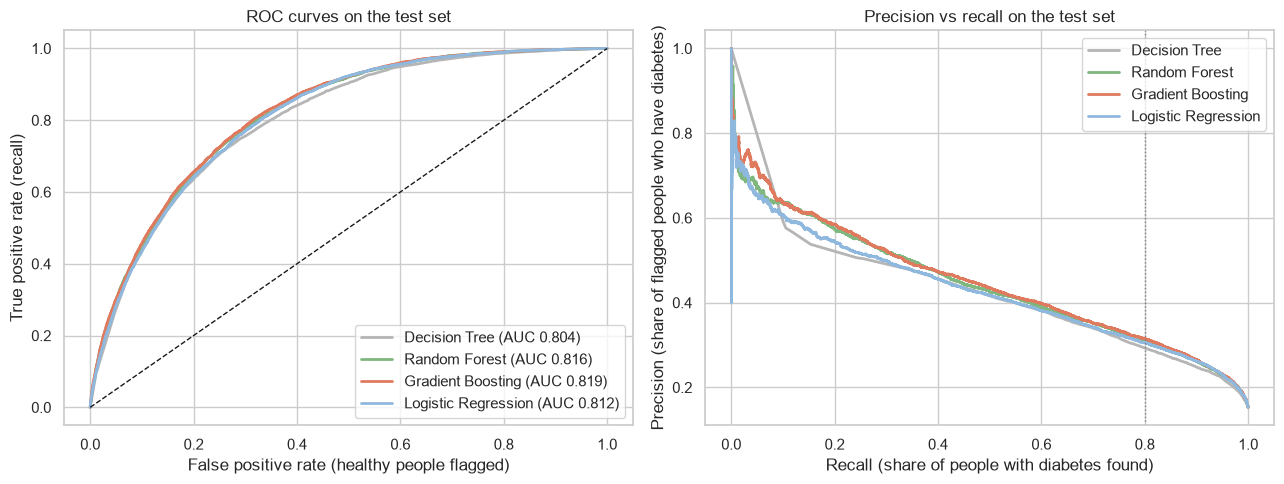

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = {"Logistic Regression": "#8fb8de", "Decision Tree": "#b5b5b5",
           "Random Forest": "#7fb77e", "Gradient Boosting": "#e07a5f"}

for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=palette[name], lw=2, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=palette[name], lw=2, label=name)

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves on the test set")
axes[0].set_xlabel("False positive rate (healthy people flagged)")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(loc="lower right")

axes[1].axvline(0.80, color="grey", ls=":", lw=1)
axes[1].set_title("Precision vs recall on the test set")
axes[1].set_xlabel("Recall (share of people with diabetes found)")
axes[1].set_ylabel("Precision (share of flagged people who have diabetes)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [9]:
best_name = compare.index[0]
final_model = tuned[best_name]
print("Final model:", best_name)

Final model: Gradient Boosting


**Decision:** Gradient Boosting has the highest ROC-AUC (0.819) and the best precision at 80% recall (0.315), so it becomes the final model. The gain over the Logistic Regression baseline is **small** (ROC-AUC 0.812 and precision 0.305). Random Forest is very close as well. This is typical for survey data: a few self-reported answers cannot separate everyone perfectly, and a more complex model cannot find signal that is not in the data. Logistic Regression remains a reasonable, easy-to-explain choice, and the difference is something to keep in mind when reading the results below.

## 6. Choosing the decision threshold

The model gives every person a **risk score** between 0 and 1. A threshold turns the score into a decision: score above the threshold means "flag for screening". A low threshold finds more people with diabetes (higher recall) but flags more healthy people too (lower precision).

**Rule used:** pick the highest threshold that still finds **at least 80% of people with diabetes**. 80% is a practical target: it catches most cases while keeping false alarms as low as possible for that coverage.

The threshold is chosen from **out-of-fold predictions on the training set** (each person is scored by a model that never saw them), so the test set stays untouched.

In [10]:
oof_scores = cross_val_predict(final_model, X_train, y_train, cv=cv5,
                               method="predict_proba", n_jobs=1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_scores)
ok = np.where(rec[:-1] >= 0.80)[0]
threshold = thr[ok[-1]]
print(f"Chosen threshold: {threshold:.3f}")
print(f"Training (out-of-fold) recall at this threshold: {rec[ok[-1]]:.3f}")
print(f"Training (out-of-fold) precision at this threshold: {prec[ok[-1]]:.3f}")

Chosen threshold: 0.144
Training (out-of-fold) recall at this threshold: 0.800
Training (out-of-fold) precision at this threshold: 0.308


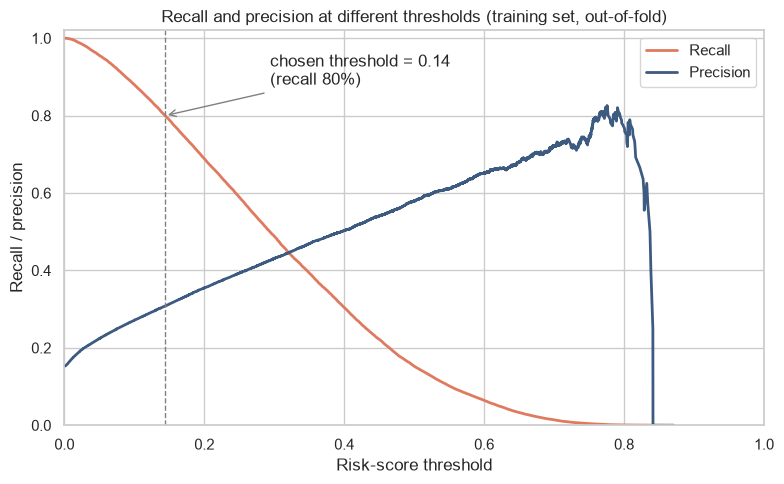

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thr, rec[:-1], color="#e07a5f", lw=2, label="Recall")
ax.plot(thr, prec[:-1], color="#3d5a80", lw=2, label="Precision")
ax.axvline(threshold, color="grey", ls="--", lw=1)
ax.annotate(f"chosen threshold = {threshold:.2f}\n(recall 80%)", (threshold, 0.80),
            xytext=(threshold + 0.15, 0.88), arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_title("Recall and precision at different thresholds (training set, out-of-fold)")
ax.set_xlabel("Risk-score threshold")
ax.set_ylabel("Recall / precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Final model results

The final model and threshold are applied **once** to the test set.

In [12]:
final_scores = final_model.predict_proba(X_test)[:, 1]
final_pred = (final_scores >= threshold).astype(int)

final_table = pd.DataFrame({
    "Notebook 01 baseline (threshold 0.5)": {
        "Recall": recall_score(y_test, tuned["Logistic Regression"].predict(X_test)),
        "Precision": precision_score(y_test, tuned["Logistic Regression"].predict(X_test)),
        "F1": f1_score(y_test, tuned["Logistic Regression"].predict(X_test)),
        "ROC-AUC": roc_auc_score(y_test, test_scores["Logistic Regression"]),
    },
    f"Final: {best_name} (threshold {threshold:.2f})": {
        "Recall": recall_score(y_test, final_pred),
        "Precision": precision_score(y_test, final_pred),
        "F1": f1_score(y_test, final_pred),
        "ROC-AUC": roc_auc_score(y_test, final_scores),
    },
}).round(3)
final_table

,Notebook 01 baseline (threshold 0.5),Final: Gradient Boosting (threshold 0.14)
Recall,0.762,0.813
Precision,0.319,0.310
F1,0.450,0.449
ROC-AUC,0.812,0.819


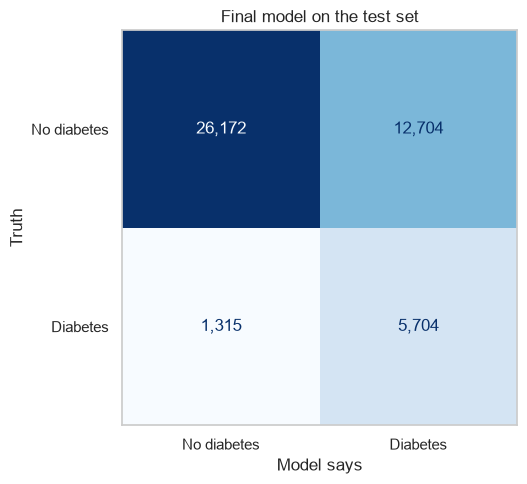

People with diabetes found:  5,704 of 7,019  (81%)
People with diabetes missed: 1,315
Healthy people flagged:      12,704 of 38,876  (33%)
Share of flagged people who really have diabetes: 31%


In [13]:
cm = confusion_matrix(y_test, final_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(
    ax=ax, cmap="Blues", values_format=",d", colorbar=False)
ax.grid(False)
ax.set_title("Final model on the test set")
ax.set_xlabel("Model says")
ax.set_ylabel("Truth")
plt.tight_layout()
plt.show()

print(f"People with diabetes found:  {tp:,} of {tp + fn:,}  ({tp / (tp + fn):.0%})")
print(f"People with diabetes missed: {fn:,}")
print(f"Healthy people flagged:      {fp:,} of {tn + fp:,}  ({fp / (tn + fp):.0%})")
print(f"Share of flagged people who really have diabetes: {tp / (tp + fp):.0%}")

**A screening view in plain numbers.** If a clinic can only follow up the people with the highest risk scores, how many cases does it find? This compares the model with picking people at random.

In [14]:
order = np.argsort(-final_scores)
sorted_truth = y_test.values[order]
total_cases = sorted_truth.sum()

rows = []
for share in [0.10, 0.20, 0.30, 0.40, 0.50]:
    n = int(len(sorted_truth) * share)
    found = sorted_truth[:n].sum()
    rows.append({"Screen the top ... of people": f"{share:.0%}",
                 "Share of all diabetes cases found": f"{found / total_cases:.0%}",
                 "Random selection would find": f"{share:.0%}"})
pd.DataFrame(rows).set_index("Screen the top ... of people")

,Share of all diabetes cases found,Random selection would find
Screen the top ... of people,,
10%,33%,10%
20%,54%,20%
30%,70%,30%
40%,81%,40%
50%,89%,50%


## 8. What drives the predictions

**Permutation importance** shuffles one column at a time and measures how much the ROC-AUC drops. A big drop means the model relies on that column. It works the same way for any model type, so it is easy to compare and explain.

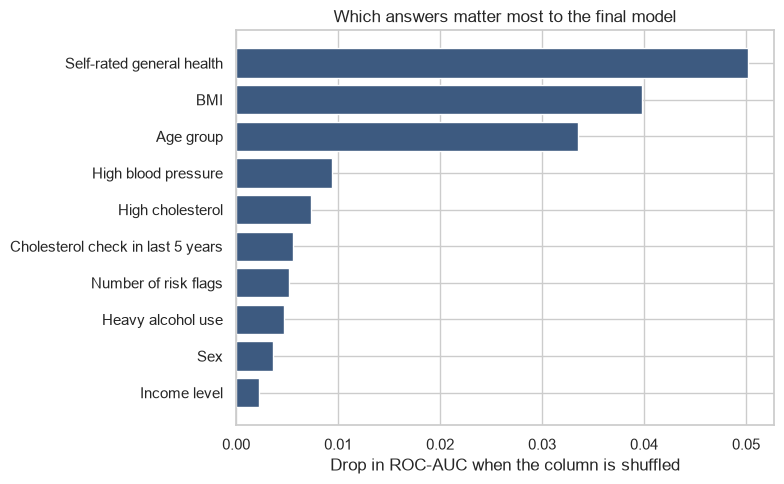

GenHlth              0.0502
BMI_capped           0.0398
Age                  0.0335
HighBP               0.0094
HighChol             0.0073
CholCheck            0.0056
RiskFactorCount      0.0052
HvyAlcoholConsump    0.0047
Sex                  0.0036
Income               0.0023
dtype: float64

In [15]:
rng_rows = X_test.sample(20000, random_state=RANDOM_STATE).index
perm = permutation_importance(final_model, X_test.loc[rng_rows], y_test.loc[rng_rows],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.Series(perm.importances_mean, index=features).sort_values()
top = importance.tail(10)

readable = {
    "GenHlth": "Self-rated general health",
    "HighBP": "High blood pressure",
    "BMI_capped": "BMI",
    "Age": "Age group",
    "HighChol": "High cholesterol",
    "Income": "Income level",
    "DiffWalk": "Difficulty walking",
    "HeartDiseaseorAttack": "Heart disease or attack",
    "CholCheck": "Cholesterol check in last 5 years",
    "RiskFactorCount": "Number of risk flags",
    "PhysHlth": "Days of poor physical health",
    "MentHlth": "Days of poor mental health",
    "Education": "Education level",
    "Sex": "Sex",
    "Smoker": "Smoker",
    "PhysActivity": "Physical activity",
    "HvyAlcoholConsump": "Heavy alcohol use",
}

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([readable.get(c, c) for c in top.index], top.values, color="#3d5a80")
ax.set_title("Which answers matter most to the final model")
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).head(10).round(4)

**Reading the chart:** a handful of answers carry most of the signal. These match what the exploratory analysis in notebook 01 showed (general health, blood pressure, BMI and age). Importance shows what the model uses, not what causes diabetes, so it should not be read as medical advice.

## 9. Is the model fair across age and income groups?

A single overall number can hide groups where the model works worse. The same final model and the same threshold are applied to each group separately. Groups are formed from the survey's age bands and income bands.

In [16]:
test = X_test.copy()
test["truth"] = y_test.values
test["flag"] = final_pred
test["score"] = final_scores

age_bins = pd.cut(test["Age"], bins=[0, 3, 6, 9, 13],
                  labels=["18-34", "35-49", "50-64", "65+"])
income_bins = pd.cut(test["Income"], bins=[0, 3, 5, 7, 8],
                     labels=["Under $20k", "$20-35k", "$35-75k", "$75k+"])


def group_report(groups, name):
    out = []
    for g, part in test.groupby(groups, observed=True):
        out.append({
            name: g,
            "People": len(part),
            "Share with diabetes": part["truth"].mean(),
            "Recall": recall_score(part["truth"], part["flag"]),
            "Precision": precision_score(part["truth"], part["flag"]),
            "Share flagged": part["flag"].mean(),
            "ROC-AUC": roc_auc_score(part["truth"], part["score"]),
        })
    return pd.DataFrame(out).set_index(name)


age_report = group_report(age_bins, "Age group")
income_report = group_report(income_bins, "Income group")
sex_report = group_report(test["Sex"].map({0: "Female", 1: "Male"}), "Sex")

for r in (age_report, income_report, sex_report):
    display(r.round(3))

,People,Share with diabetes,Recall,Precision,Share flagged,ROC-AUC
Age group,,,,,,
18-34,4559,0.023,0.234,0.203,0.027,0.824
35-49,8700,0.076,0.602,0.286,0.161,0.836
50-64,15832,0.166,0.810,0.325,0.414,0.815
65+,16804,0.215,0.871,0.305,0.614,0.752


,People,Share with diabetes,Recall,Precision,Share flagged,ROC-AUC
Income group,,,,,,
Under $20k,7573,0.247,0.898,0.362,0.612,0.783
$20-35k,9038,0.190,0.858,0.321,0.507,0.797
$35-75k,15114,0.137,0.775,0.285,0.373,0.810
$75k+,14170,0.096,0.697,0.268,0.251,0.830


,People,Share with diabetes,Recall,Precision,Share flagged,ROC-AUC
Sex,,,,,,
Female,25531,0.142,0.803,0.313,0.364,0.831
Male,20364,0.167,0.823,0.307,0.447,0.804


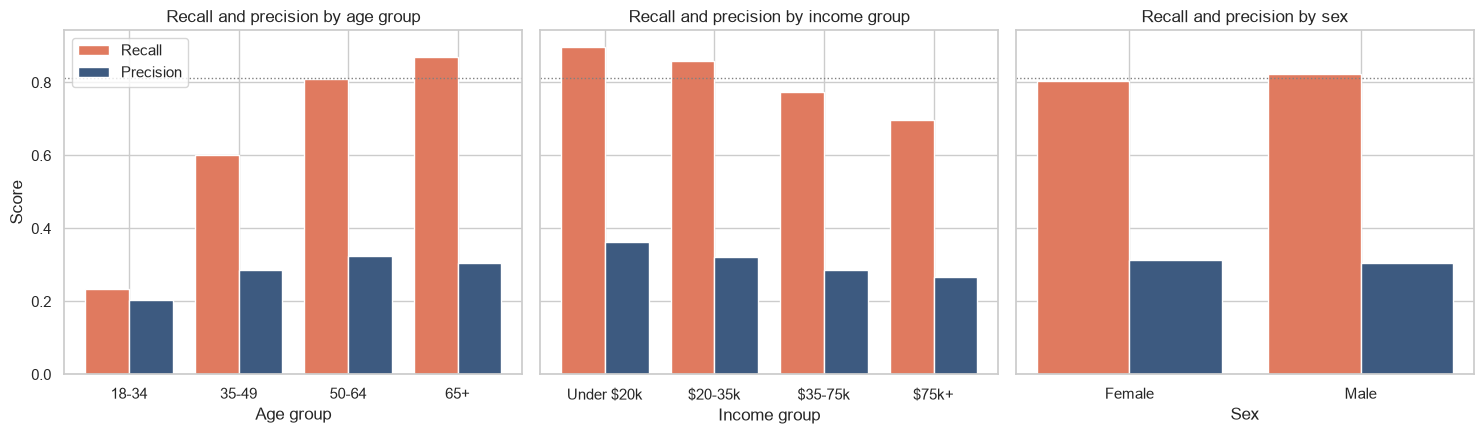

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, report, title in zip(axes, (age_report, income_report, sex_report),
                             ("Age group", "Income group", "Sex")):
    x = np.arange(len(report))
    ax.bar(x - 0.2, report["Recall"], width=0.4, color="#e07a5f", label="Recall")
    ax.bar(x + 0.2, report["Precision"], width=0.4, color="#3d5a80", label="Precision")
    ax.set_xticks(x)
    ax.set_xticklabels(report.index)
    ax.set_title(f"Recall and precision by {title.lower()}")
    ax.set_xlabel(title)
    ax.axhline(recall_score(y_test, final_pred), color="grey", ls=":", lw=1)
axes[0].set_ylabel("Score")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

**What to notice:**

- **Age is the biggest gap.** Recall is 87% for people over 65 and 81% for ages 50-64, but only 60% for ages 35-49 and **only 23% for ages 18-34**. Most young adults with diabetes get a risk score below the single threshold and would not be flagged. The ranking quality (ROC-AUC) within the young groups is good (0.82 to 0.84), so the problem looks like the one-size-fits-all threshold rather than the ranking: age is one of the strongest signals, and young people tend to get a low score even when they have diabetes. (Ranking is weakest for people over 65, ROC-AUC 0.75.) The model flags 61% of people over 65 but only 3% of those aged 18-34.
- **Income shows the reverse pattern.** Recall is 90% for people under $20k and 70% for people at $75k or more. Lower-income groups have a higher diabetes rate, so more of them cross the threshold. The model therefore finds fewer cases among higher-income people, although it also flags fewer of them.
- **Sex:** results are close for women (recall 80%) and men (82%).
- The youngest group has few cases (about 2% of 4,559 people), so its numbers are less certain than the others.

**Consequence:** the 81% overall recall hides a weak spot. Used as it is, the model would be much less useful for finding diabetes in young adults. A separate threshold per age group (accepting more false alarms in the younger groups) is the obvious next step, and is listed below rather than done here, because it needs a decision by the health team about how many false alarms each group can bear.

## 10. Conclusions and next steps

**Conclusions**

- Three tree-based models were tuned with grid search and cross-validation and compared with the Logistic Regression baseline. The final model is Gradient Boosting.
- It is only **slightly** better than the baseline (ROC-AUC 0.819 vs 0.812; precision 0.315 vs 0.305 at 80% recall). The answers in the survey carry a limited amount of information, and a more complex model does not change that much.
- With the threshold set to find about 80% of people with diabetes (81% on the test set), the model flags 33% of healthy people, and only 31% of flagged people really have diabetes. It is a **screening aid** that tells a clinic who to test first, not a diagnosis.
- Screening the 30% of people with the highest scores finds about 70% of all cases, against 30% for random selection.
- Self-rated general health, BMI, age and blood pressure matter most to the model.
- **Weak spot:** with one threshold for everyone, the model finds only 23% of cases among people aged 18-34 (60% at 35-49), against 81% to 87% at ages 50 and above. It also finds fewer cases among higher-income people (70%) than among lower-income people (90%).

**Limitations**

- Self-reported survey data from 2015; may not describe the population today.
- Prediabetes and diabetes are combined, and type 1 and type 2 cannot be told apart.
- Only a small grid of settings was searched, to keep the run time practical.
- The model shows association, not causation.

**Next steps**

- Test the model on newer survey years (for example BRFSS 2022) to check whether it still works.
- Add lab measurements such as blood sugar to see how much they improve the model.
- Try group-specific thresholds (especially for adults under 50) and agree on acceptable false-alarm levels with a health professional.
- Run a small pilot where the model's flags are followed by real tests, and measure the false-alarm cost.